# Resource Allocation In The Global South

###By Vaishvik Polneedi, Adarsh Ramanujam, Sunny Zhu

Using data from the World Bank, how do countries within the Global South allocate resources towards development and better QoL, and how AI might help with more efficient allocation soon?

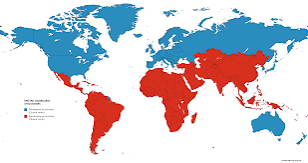

## Importing And Cleaning The Dataset

First, we need to both call the dataset through the API query and clean it to make sure that we have access to it. We need it actually workable so that we can potentially create an AI solution to some of the problems that countries in the Global South have relating to resource allocation. The countries selected are currently developing countries, all affected by colonialism in Africa, Asia, and Latin America. They represent countries that could benefit from having a better framework to give back to their people and develop such that their Quality of Life improves.


In [ ]:
import numpy as np
import pandas as pd

import requests

indicator_id = "IQ.CPA.IRAI.XQ"
aggregate_country_codes = 'AFG; BGD; BEN; BTN; BDI; CPV; KHM; CMR; CAF; TCD; COM; COD; COG; CIV; DJI; DMA; ERI; SWZ; ETH; GMB; GHA; GIN; GNB; GUY; HTI; HND; KEN; XKX; KGZ; LAO; LBR; MDG; MLI; MRT; MNG; MOZ; MMR; NPL; NIC; NER; NGA; PAK; PNG; RWA; SEN; SLE; YEM; VNM' #used AI to fix syntax error
country_code = aggregate_country_codes

IRIA_url = f"https://api.worldbank.org/v2/country/{country_code}/indicator/{indicator_id}?date=2020:2025&format=json&per_page=1000"

response = requests.get(IRIA_url)
data = response.json()

if len(data) > 1 and data[1]:
    records = data[1]

    formatted_data = [
        {
            "Country": record["country"]['value'],
            "ISO3": record["countryiso3code"],
            "Year": record["date"],
            "IRIA Score": record["value"],
        }
        for record in records #
    ]
    IRIA_df = pd.DataFrame(formatted_data)

    IRIA_clean = IRIA_df.dropna().reset_index(drop=True)
    display(IRIA_clean.head(100))
else:
    print("No data found for this query.")

,Country,ISO3,Year,IRIA Score
0,Afghanistan,AFG,2025,1.766667
1,Afghanistan,AFG,2024,1.700000
2,Afghanistan,AFG,2023,1.658333
3,Afghanistan,AFG,2022,1.725000
4,Afghanistan,AFG,2020,2.658333
...,...,...,...,...
95,Ghana,GHA,2025,3.491667
96,Ghana,GHA,2024,3.408333
97,Ghana,GHA,2023,3.408333
98,Ghana,GHA,2022,3.366667


The data is now cleaned, and now to understand the scope of the project, we need to have an accurate visualizations to see how these countries are improving in their IRIA score. What is an IRIA Score you may ask? Since this project surrounds resource allocation, the IRIA measures how well the different policy and institutional dimensions of an effective poverty reduction and growth strategy. The criteria have evolved over time, reflecting lessons learned and mirroring the evolution of the development paradigm. They are evaluated across 16 different criteria, including economic management, structural policies, policies for social inclusion and equity; and public sector management, among other criteria that help measure how developed a country is becoming.

## Visualizing Change Over Time


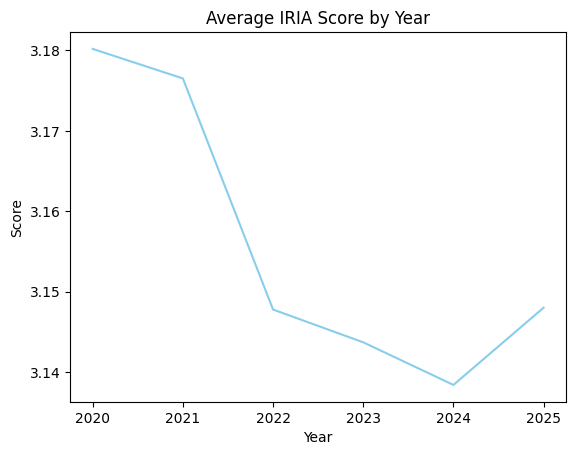

In [ ]:
import matplotlib.pyplot as plt


ax = IRIA_clean.groupby('Year')['IRIA Score'].mean().plot(kind='line', color='skyblue')
plt.title('Average IRIA Score by Year')
plt.ylabel('Score')
plt.show()

This gives us an image of stagnation in the IRIA since COVID, since not much changes from year to year in the index (max change of approximately 0.02 between years). This may be useful for coming up with a solution for using AI to help improve specific aspects of their development to increase this IRIA score (and thus, make actual progress where it matters). Let's switch to QGIS to see which areas may be stagnant over these past 6 years.


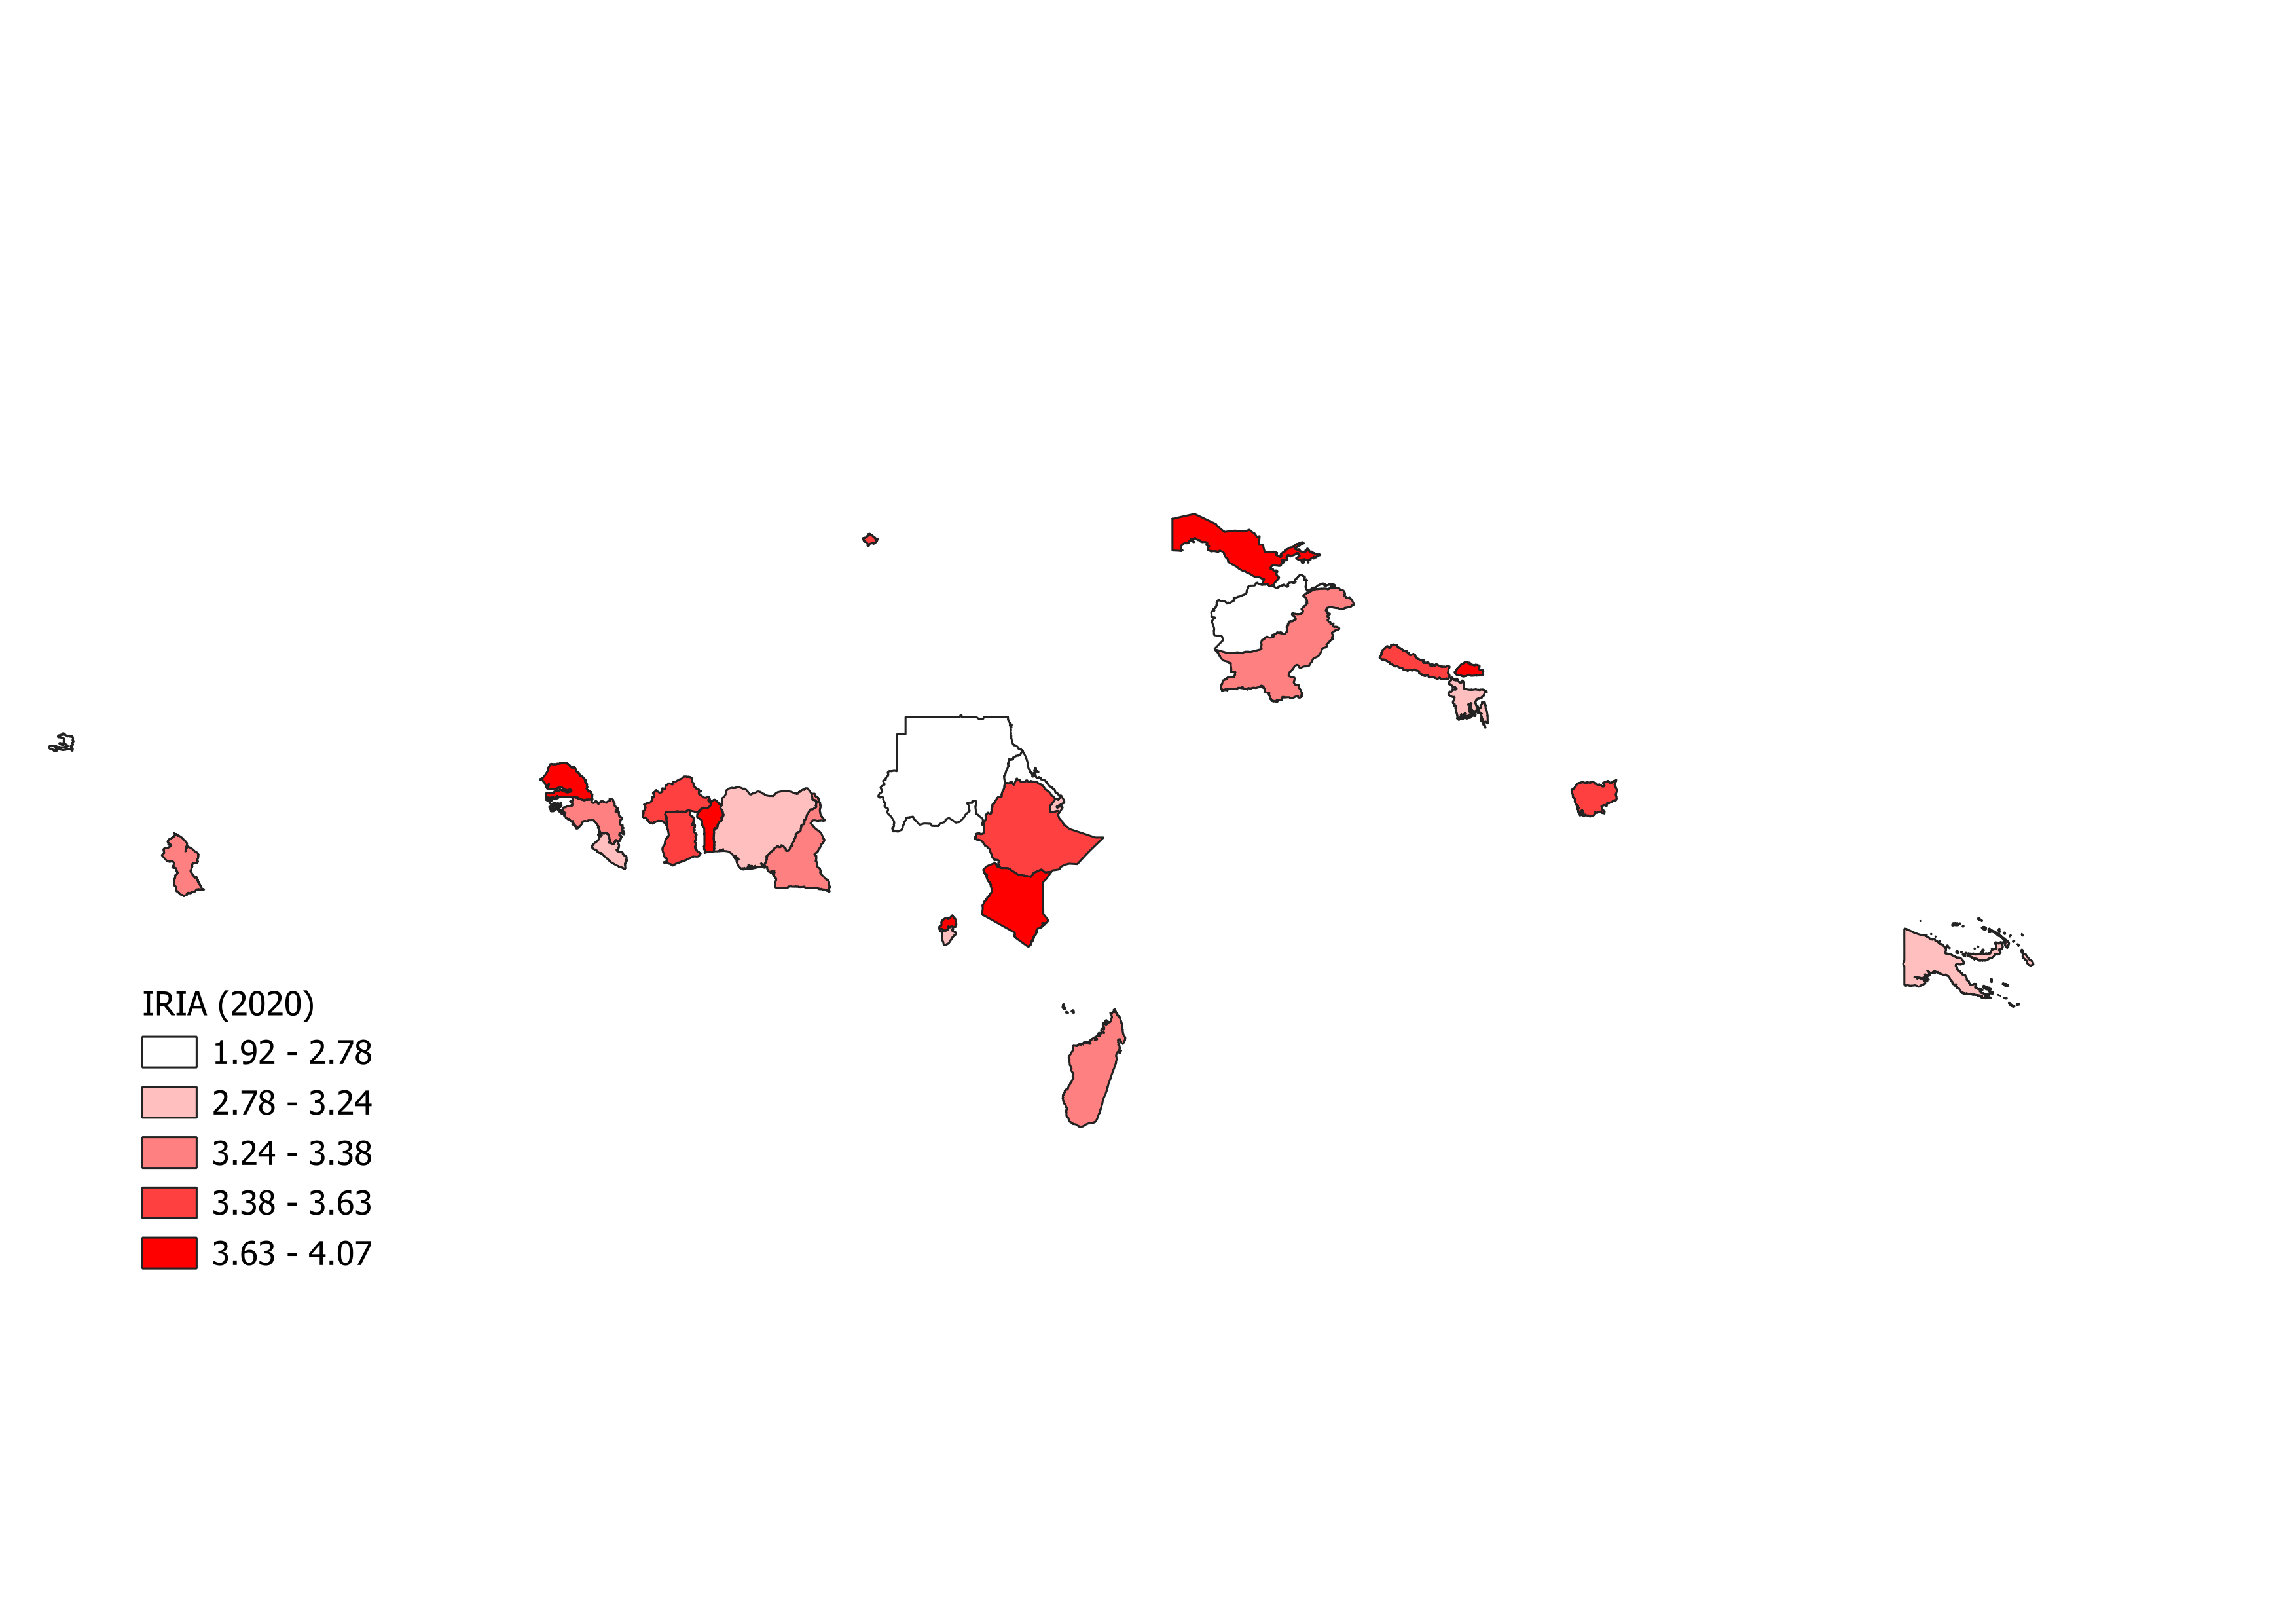

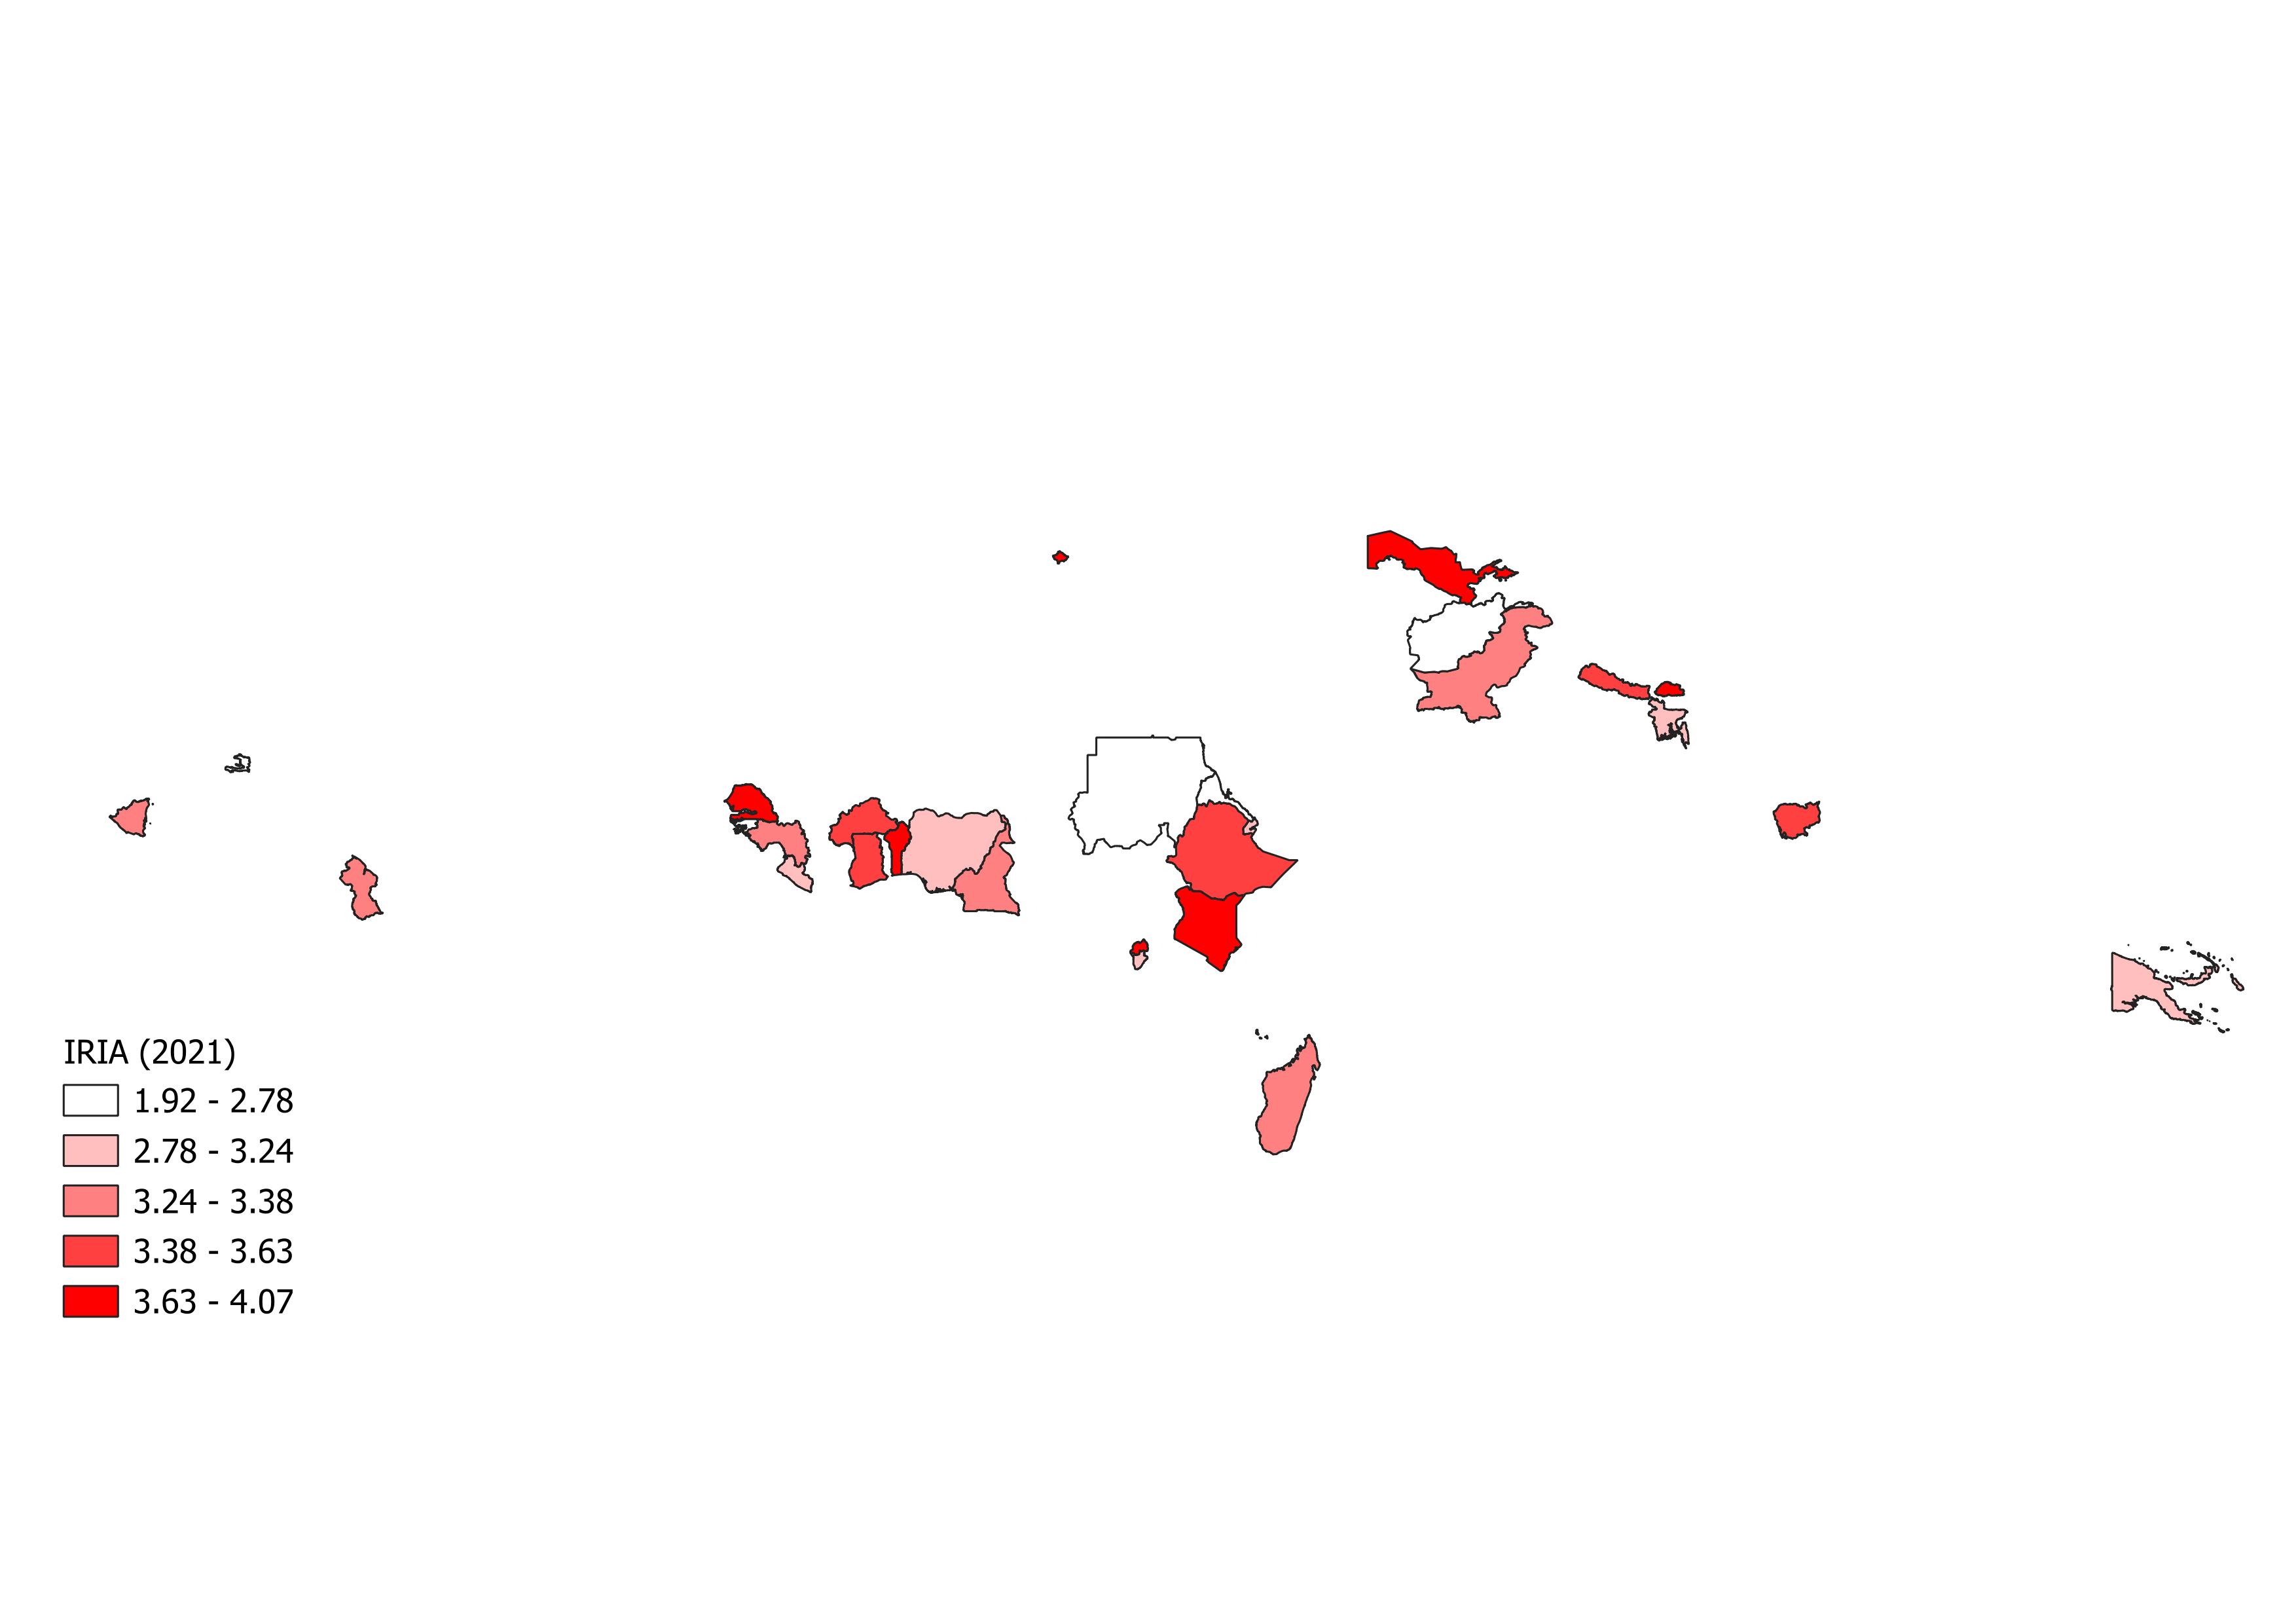

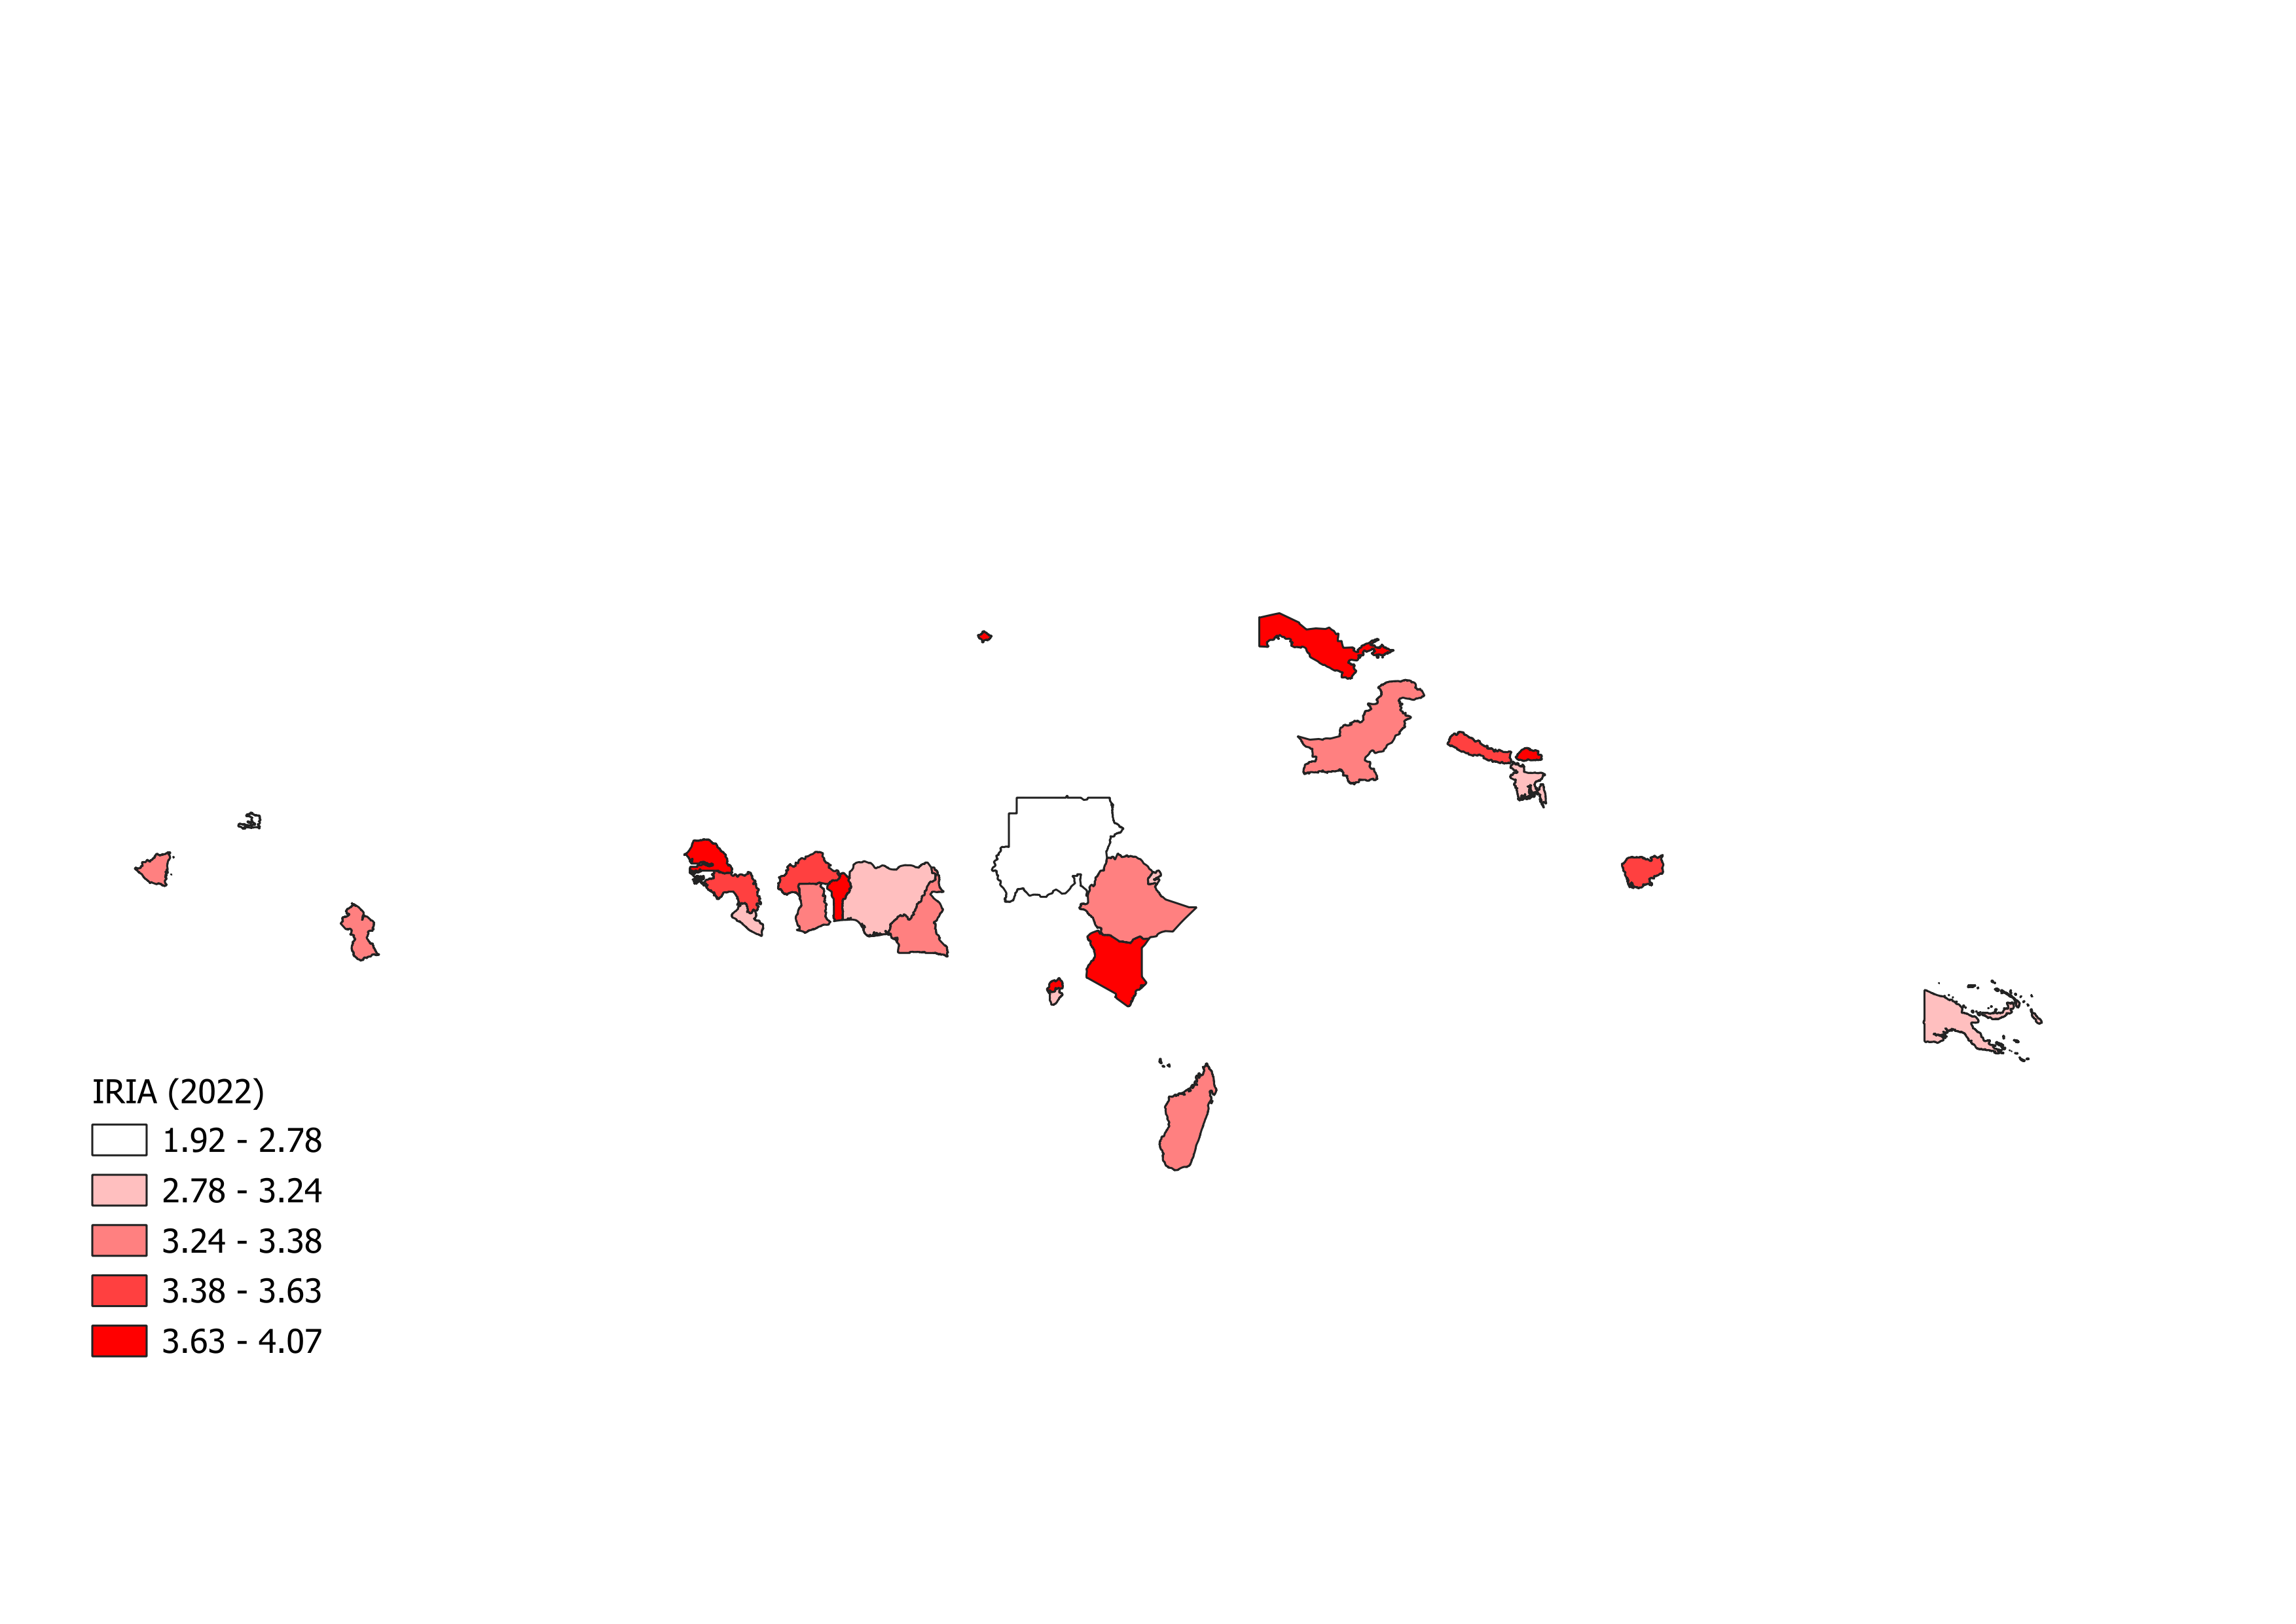

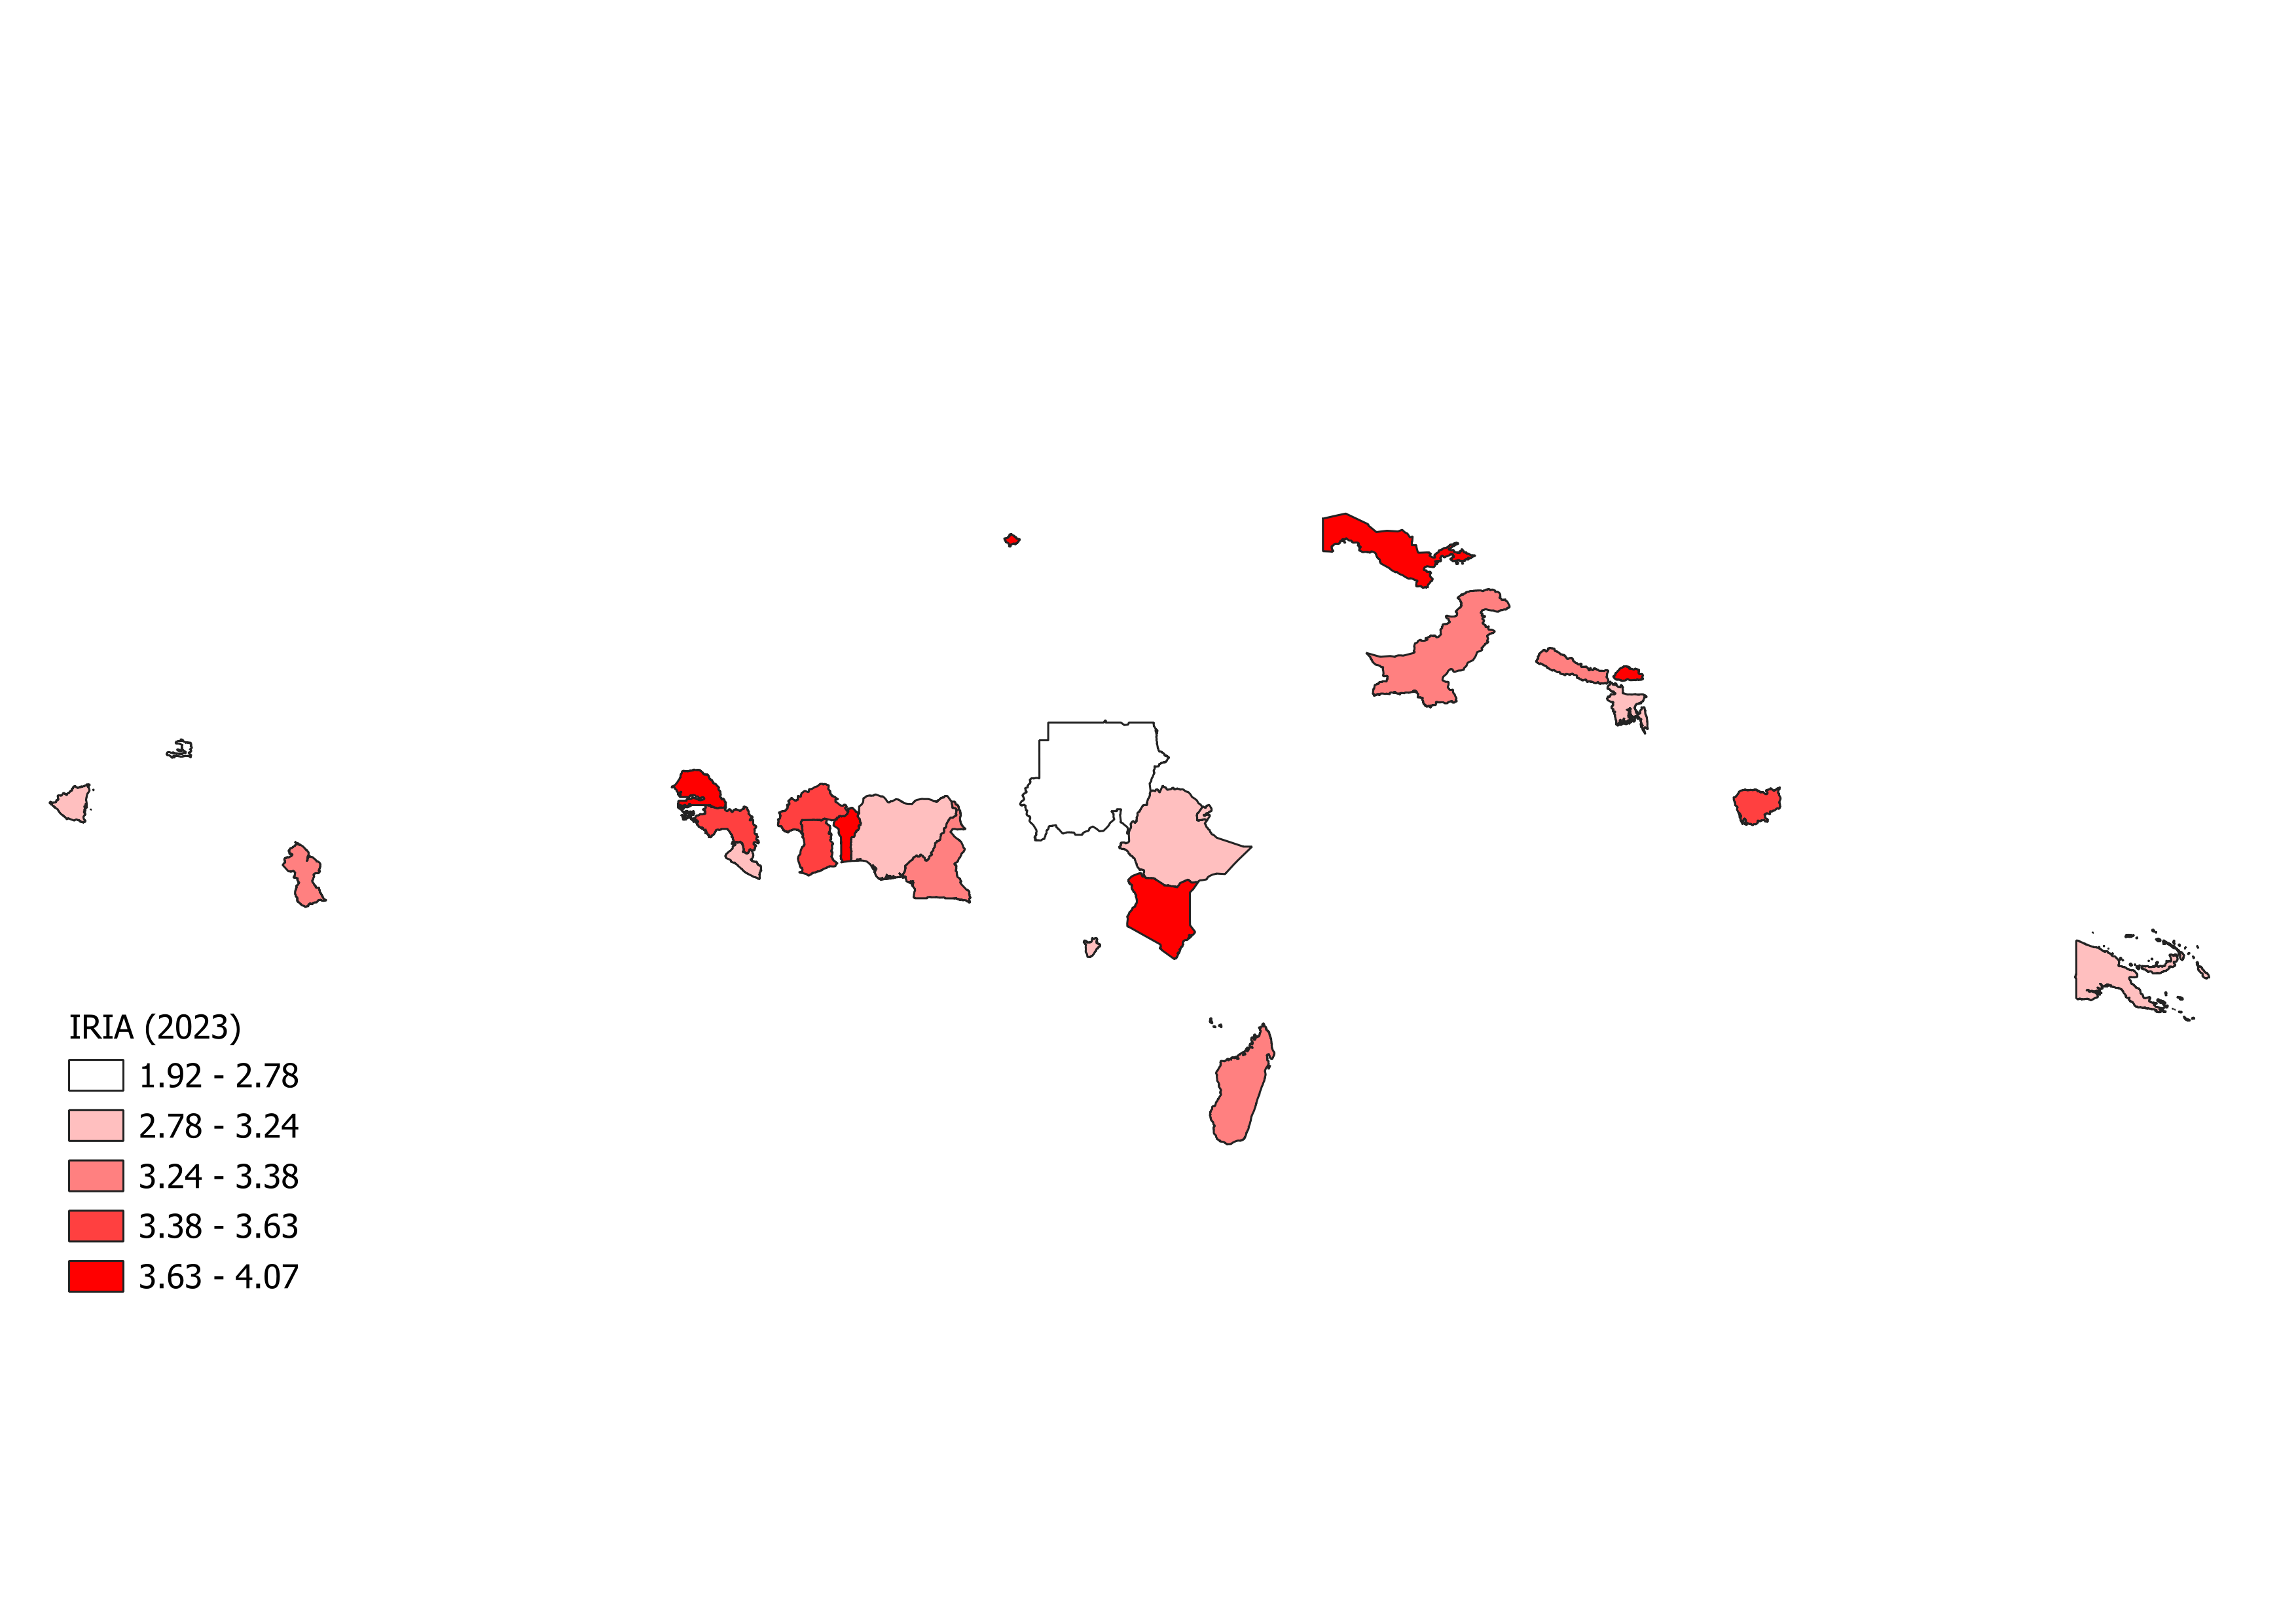

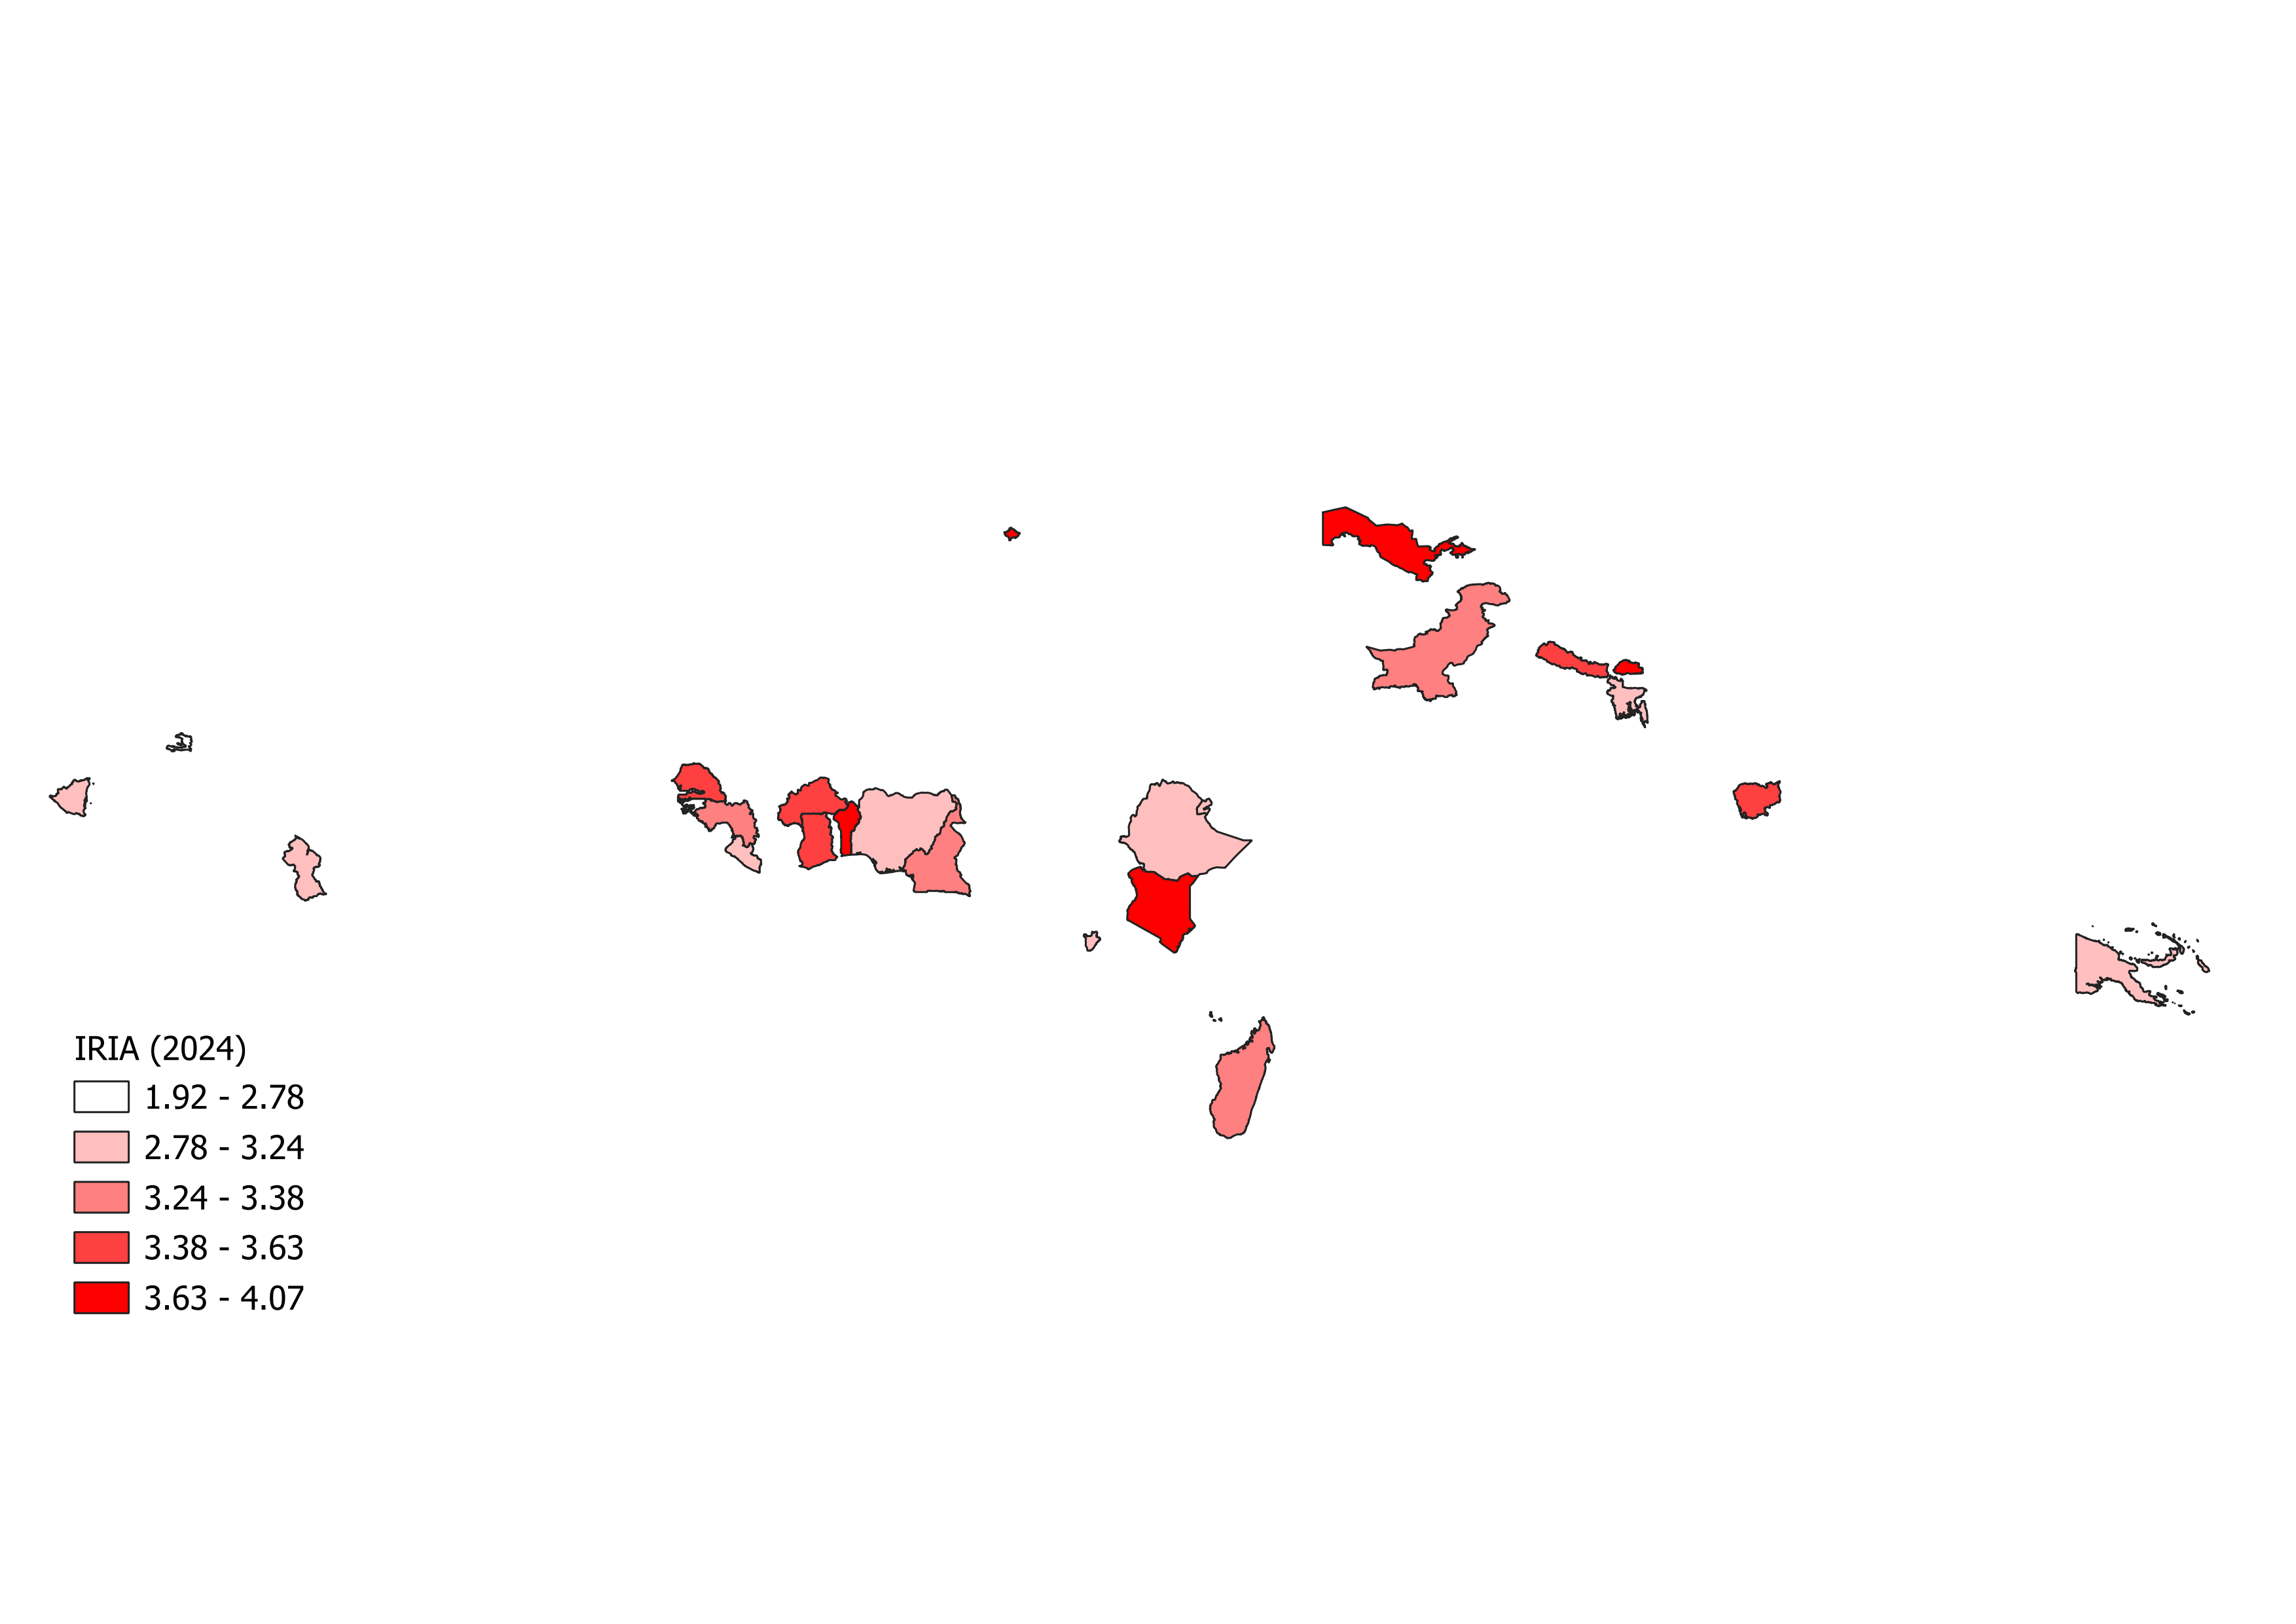

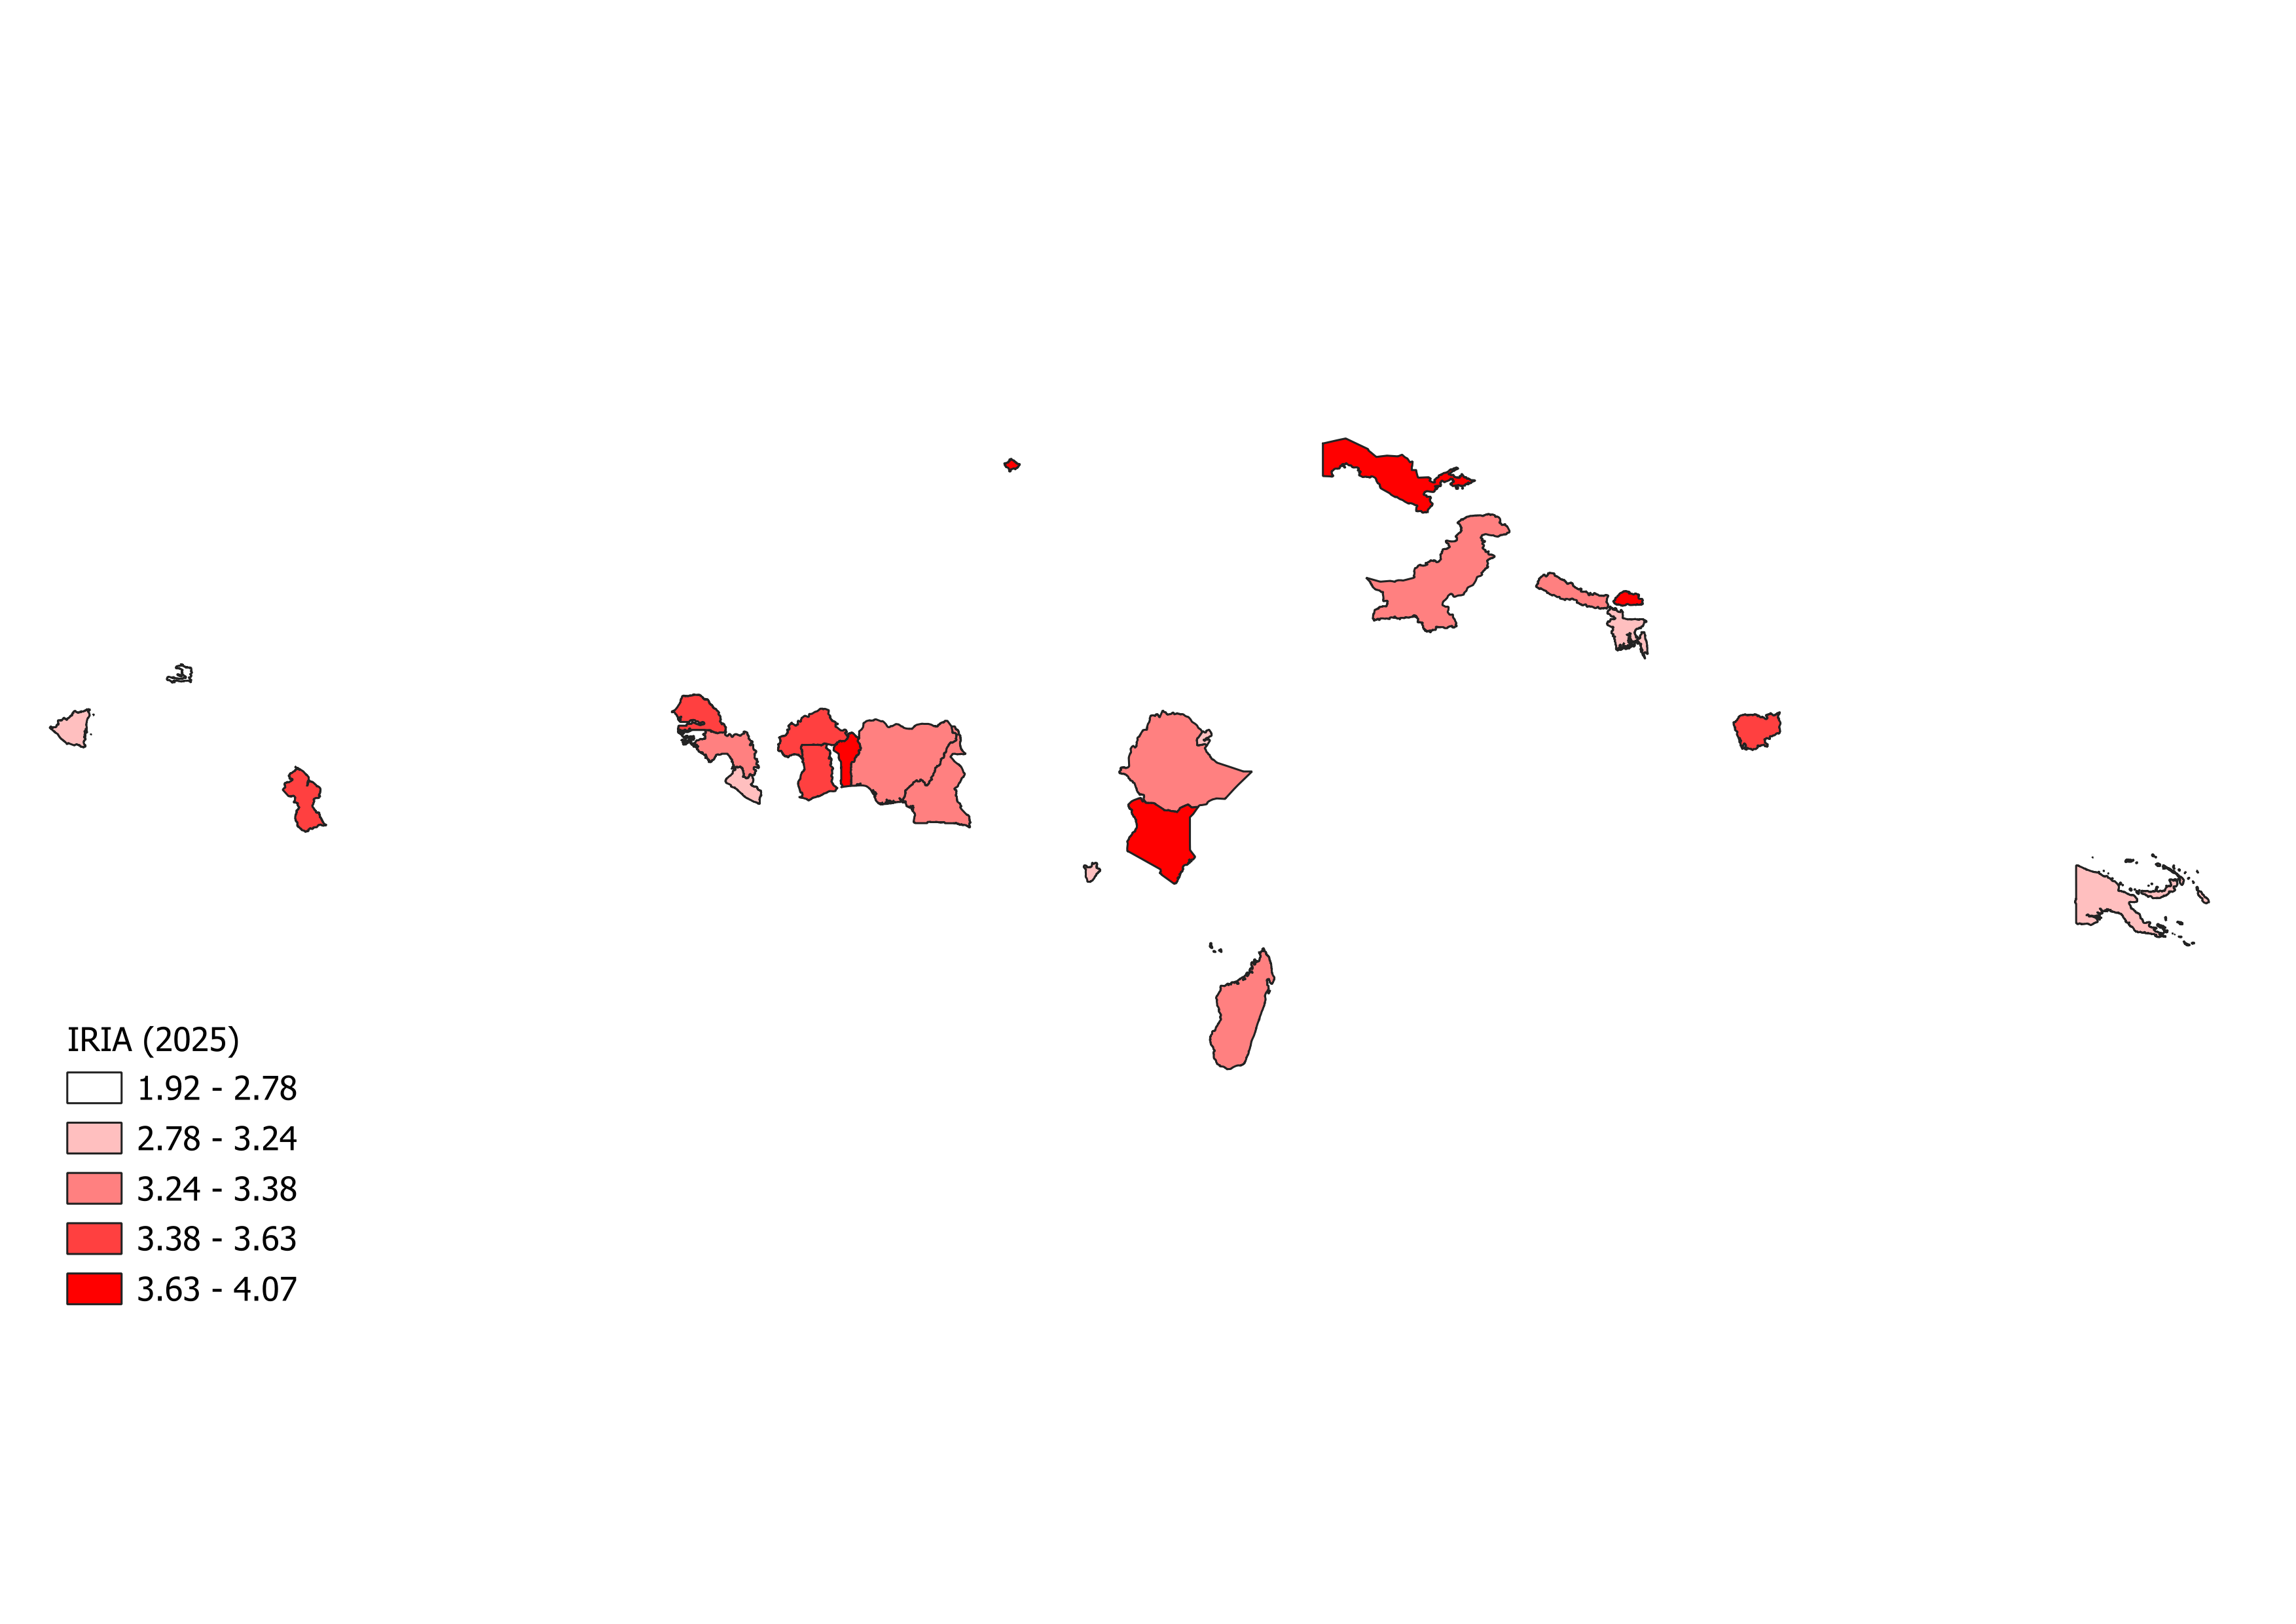

This QGIS visualizations also point towards the same conclusion: stagnation in these Global South countries is prevalent. Now that we have an understanding of the trend and maybe what it relates to, how do we implement AI into the solution of helping these countries improve their IRIA?

## Implementing AI through Compliance and Taking Action


In Sending and Lie's study from 2015 analyzing the impact of World Bank global benchmarks and how they affect and influence the development and guidance of countries, they outline a key pitfall in these benchmarks: that global authority has a limit. They demonstrate that abstract numerical benchmarks often fail to exert lasting influence over a country's actual behavior. Because these scores are frequently treated as high-level negotiating tools rather than concrete reform plans, countries can stall on genuine institutional progress while appearing compliant on paper.

Through incorporating a Natural Language Processing tool, we may be able to allow for a more effective system rather than a numerical rating that has little to no meaning for the average bureaucrat. Our program can take all the governance documents from the World Bank and compare them to the country's actual domestic texts, such as: public procurement portals, local legislation, and budget frameworks. Through this, humans can analyze the difference between the local laws and the World Map benchmarks for progress, grounding these IRIA and CPIA scores in actual meaning.

## Building the NLP Policy-to-Benchmark Alignment Tool
To move beyond abstract numerical scores, we implement an NLP system using Sentence Transformers. This program takes World Bank benchmark goals (representing the IRIA criteria) and maps local policy text against them, calculating a **Semantic Alignment Score** and identifying critical policy gaps.

In [ ]:
!pip install -q sentence-transformers

In [ ]:
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# 1 Initialize the NLP Model
model = SentenceTransformer('all-MiniLM-L6-v2')

# 2 World Bank Benchmark Standards
benchmarks = {
    "Economic Management": "Maintain a sustainable fiscal policy with transparent debt management, stable inflation controls, and clear public expenditure frameworks.",
    "Social Inclusion & Equity": "Ensure equitable access to education, healthcare, and social safety nets for marginalized and vulnerable populations.",
    "Public Sector Governance": "Implement robust anti-corruption measures, ensure judicial independence, and maintain public procurement transparency to prevent embezzlement.",
    "Structural Reforms": "Promote competitive trade policies, reduce barriers for private sector businesses, and secure land and property rights."
}

# 3. Define Sample Domestic Policy Text
domestic_policies = [
    "The state shall allocate 15% of the annual budget to secondary school development and expand primary healthcare clinics in rural districts.",
    "An online portal will be launched for publishing government tenders, requiring all bids to be open for public audit within 30 days.",
    "To encourage trade, we are simplifying the business registration process to take under 48 hours and cutting import tariffs on solar panels."
]

# 4 Compute Embeddings
benchmark_titles = list(benchmarks.keys())
benchmark_texts = list(benchmarks.values())

benchmark_embeddings = model.encode(benchmark_texts)
domestic_embeddings = model.encode(domestic_policies)

# 5 Compute Similarity Matrix (Domestic Policies vs. Benchmarks)
similarity_matrix = cosine_similarity(domestic_embeddings, benchmark_embeddings)

# Create a structured report of the results
report_data = []
for i, policy in enumerate(domestic_policies):
    for j, benchmark in enumerate(benchmark_titles):
        score = similarity_matrix[i][j]
        report_data.append({
            "Domestic Policy Snippet": policy[:80] + "...",
            "World Bank Benchmark": benchmark,
            "Semantic Alignment Score": round(float(score), 4)
        })

report_df = pd.DataFrame(report_data)

# Display alignment overview
print("=== POLICY ALIGNMENT MATRIX ===")
display(report_df.sort_values(by="Semantic Alignment Score", ascending=False))


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

=== POLICY ALIGNMENT MATRIX ===


,Domestic Policy Snippet,World Bank Benchmark,Semantic Alignment Score
1,The state shall allocate 15% of the annual bud...,Social Inclusion & Equity,0.3541
6,An online portal will be launched for publishi...,Public Sector Governance,0.3213
11,"To encourage trade, we are simplifying the bus...",Structural Reforms,0.3103
0,The state shall allocate 15% of the annual bud...,Economic Management,0.2171
7,An online portal will be launched for publishi...,Structural Reforms,0.1803
3,The state shall allocate 15% of the annual bud...,Structural Reforms,0.1636
4,An online portal will be launched for publishi...,Economic Management,0.1460
10,"To encourage trade, we are simplifying the bus...",Public Sector Governance,0.1356
2,The state shall allocate 15% of the annual bud...,Public Sector Governance,0.1249
5,An online portal will be launched for publishi...,Social Inclusion & Equity,0.0853


In [ ]:
# 6 Identify the Policy Gaps (where alignment is low)
gap_threshold = 0.25

print("=== DETECTED POLICY GAPS ===")
for benchmark_title in benchmark_titles:
    # Find the maximum alignment score this benchmark received from any domestic policy snippet
    benchmark_idx = benchmark_titles.index(benchmark_title)
    max_alignment = np.max(similarity_matrix[:, benchmark_idx])

    if max_alignment < gap_threshold:
        print(f"❌ CRITICAL GAP DETECTED: '{benchmark_title}' has no matching domestic policy provisions. (Max Alignment: {max_alignment:.2f})")
        print(f"   Expected Standard: {benchmarks[benchmark_title]}\n")
    else:
        print(f"✅ Covered: '{benchmark_title}' is addressed by domestic frameworks. (Max Alignment: {max_alignment:.2f})")


=== DETECTED POLICY GAPS ===
❌ CRITICAL GAP DETECTED: 'Economic Management' has no matching domestic policy provisions. (Max Alignment: 0.22)
   Expected Standard: Maintain a sustainable fiscal policy with transparent debt management, stable inflation controls, and clear public expenditure frameworks.

✅ Covered: 'Social Inclusion & Equity' is addressed by domestic frameworks. (Max Alignment: 0.35)
✅ Covered: 'Public Sector Governance' is addressed by domestic frameworks. (Max Alignment: 0.32)
✅ Covered: 'Structural Reforms' is addressed by domestic frameworks. (Max Alignment: 0.31)


####Results:

The generated semantic alignment score for each policy snippet from the World Bank policy gave a clearer picture of which World Bank Benchmarks succeeded and failed in these countries. For example, the top three World Bank Benchmarks observed were 'Social Inclusion & Equity'(0.35), 'Public Sector Governance'(0.32), and 'Structural Reforms'(0.32). These top benchmarks managed to be above the set threshold for 0.25 and demonstrate that there is significant domestic provisions addressing these three areas.

Conversely, we see that a critical policy gap was detected for 'Economic Management'(0.21), failing to reach the set threshold of 0.25. This gap indicates a significant lack of domestic policy addressing this area, with no country reaching the expected standard of: 'Maintain a sustainable fiscal policy with transparent debt management, stable inflation controls, and clear public expenditure frameworks.'

## Proposed Solution: AI-Assisted Resource Allocation

Our proposed solution is an AI-assisted resource allocation system designed to help countries in the Global South translate development benchmarks into concrete decisions about how limited resources can be used. Our current NLP model provides the first step by comparing World Bank development benchmarks with domestic policy documents and identifying areas where policies may not adequately address development goals.


The next step is to connect these policy gaps with socioeconomic and government spending data. The system could incorporate information about healthcare, education, infrastructure, poverty, employment, demographics, and government budgets. By combining these datasets, AI could help identify which areas have the greatest development needs and simulate how different resource-allocation strategies might affect quality-of-life indicators.


Rather than allowing AI to make decisions automatically, the system would function as a decision-support tool. Policymakers could compare multiple scenarios, including their estimated costs, potential benefits, geographic effects, and levels of uncertainty. Human decision-makers would remain responsible for choosing how resources are ultimately allocated.


####Roadmap

Phase 1 — Build the Data Foundation:
Collect and standardize World Bank indicators, government budgets, demographic information, and quality-of-life measurements across selected countries.

Phase 2 — Expand Policy Alignment:
Expand our existing Sentence-BERT model to analyze real government legislation, budget documents, procurement policies, and development plans. The system would identify where domestic policies align with or fall short of development benchmarks.

Phase 3 — Map Resource Allocation:
Connect government spending to specific sectors and regions. This would allow us to identify where resources are currently being directed and whether those allocations correspond with identified development needs.

Phase 4 — Develop AI Impact Models:
Use historical data to examine relationships between resource allocation and development outcomes. Machine-learning and statistical models could then estimate the potential effects of different investment strategies.

Phase 5 — Create a Resource Allocation Simulator:
Develop an interactive dashboard where policymakers can test different budget scenarios. For example, they could compare the potential effects of increasing healthcare, education, infrastructure, or social protection spending.

Phase 6 — Pilot the System:
Test the system in one country or region using a limited number of development sectors. Compare the model's recommendations and predictions with actual outcomes.

Phase 7 — Human Oversight and Evaluation:
Establish human review, transparency requirements, bias testing, and regular evaluation of model accuracy. AI recommendations should remain advisory rather than automatically determining government spending.

Phase 8 — Scale and Continuously Monitor:
If the pilot demonstrates useful results, expand the system to additional countries and sectors. Continuously compare predicted outcomes with actual outcomes and update the models as new data becomes available.

Our overall goal with this solution is to create a continuous development cycle:


Development Benchmark → Policy Gap Detection → Resource Prioritization → AI Scenario Modeling → Human Decision → Outcome Measurement → Model Improvement


This would move the project beyond simply measuring whether countries meet development benchmarks and toward using data and AI to help governments evaluate how limited resources could be allocated toward development and improved quality of life.

Sources Used:

CPIA criteria 2024 Operations Policy and Country Services World Bank Group. (n.d.). https://thedocs.worldbank.org/en/doc/5573e58edce388c9de286a026bb604ff-0410012025/original/CPIA-Criteria-2024.pdf

SENDING, O. J., & LIE, J. H. S. (2015). The limits of global authority: World Bank benchmarks in Ethiopia and Malawi. Review of International Studies, 41(5), 993–1010. doi:10.1017/S026021051500042X